# 03 · The hexagon grid, and what each hexagon holds

> **What and why**
>
> - We put every hotspot into a hexagon from the H3 grid. All hexagons at one level have about the same area, so places can be compared fairly.
> - For every hexagon where a fire was ever seen, we store its land cover, peat, people and country.
> - These cell facts help the model learn why the two sensors differ, and they let users pick a place by name.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
from fireharmony import aggregate as AG
GOLD = [str(AG.gold_path(y)) for y in C.years() if AG.gold_path(y).exists()]
STATIC = C.work('features', 'cell_static_l5.parquet')
from matplotlib.colors import LogNorm
s = pd.read_parquet(STATIC)

## 1. One grid, several zoom levels

Each hexagon splits into seven smaller ones at the next level. Level 5 is our main analysis cell. The app shows levels 3 and 4 when zoomed out.

In [2]:
g19 = str(AG.gold_path(2019))
levels = con.execute(f'''
  SELECT lvl, h3_get_hexagon_area_avg(lvl, 'km^2') AS km2,
         (SELECT count(DISTINCT h3_cell_to_parent(cell, lvl)) FROM '{g19}' WHERE n_main > 0) AS active_2019
  FROM (SELECT unnest([3, 4, 5]) AS lvl)''').df()
levels.round(1)

,lvl,km2,active_2019
0,3,12393.4,10748
1,4,1770.3,54955
2,5,252.9,261672


## 2. What each hexagon holds

In [3]:
grid = pd.read_parquet(C.work('panel_l5', 'universe.parquet'))
pop = pd.read_parquet(C.work('features', 'population.parquet'))
print(f"{len(s):,} hexagons where a satellite ever saw any hotspot; {len(grid):,} of them had a vegetation fire (our grid)")
print(f"world population in our population layer: {pop.pop2000.sum() / 1e9:.2f} billion (2000), {pop.pop2020.sum() / 1e9:.2f} billion (2020)")
peat = pd.read_parquet(C.work('features', 'peat.parquet'))
print(f"peat layer: {peat.peat_km2.sum() / 1e6:.2f} million km2 in {len(peat):,} hexagons (PEATMAP reports 4.23); "
      f"{s.peat_km2.sum() / 1e6:.2f} million km2 of it in the {(s.peat_frac > 0).sum():,} hexagons where a satellite saw a hotspot")
print(f"{s.pop2020.sum() / 1e9:.2f} billion people live in these hexagons (2020)")
s[['lat', 'lon', 'country', 'state', 'biome', 'lc_forest', 'lc_savanna', 'lc_cropland', 'peat_frac', 'pop2020']].sample(5, random_state=1).round(3)

424,480 hexagons where a satellite ever saw any hotspot; 413,699 of them had a vegetation fire (our grid)
world population in our population layer: 6.05 billion (2000), 8.00 billion (2020)
peat layer: 4.23 million km2 in 106,075 hexagons (PEATMAP reports 4.23); 3.26 million km2 of it in the 86,236 hexagons where a satellite saw a hotspot
7.89 billion people live in these hexagons (2020)


,lat,lon,country,state,biome,lc_forest,lc_savanna,lc_cropland,peat_frac,pop2020
246498,15.672,80.183,India,Andhra Pradesh,tropical cropland,0.000,0.009,0.834,0.0,73746.486
122654,51.059,-110.274,Canada,Alberta,temperate grassland,0.000,0.000,0.224,0.0,64.888
358057,-7.121,140.818,Indonesia,Papua,tropical forest,0.937,0.018,0.000,0.0,2742.126
299515,-11.038,-39.635,Brazil,Bahia,tropical grassland,0.000,0.000,0.000,0.0,13106.732
92119,42.460,85.524,China,Xinjiang,temperate grassland,0.000,0.000,0.000,0.0,1857.294


## 3. Where the fires are

We sum all vegetation hotspots seen by Suomi NPP from 2013 to 2019 in level 4 hexagons (about 1,770 km2), on an equal area world map.

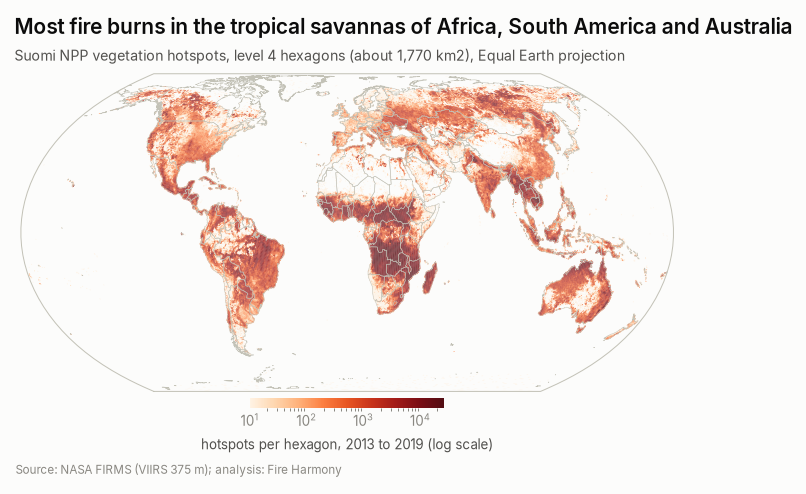

In [4]:
hexes = con.execute(f'''
  SELECT h3_cell_to_boundary_wkt(h3_cell_to_parent(cell, 4)) AS w, sum(n_main) AS n
  FROM read_parquet({GOLD}) WHERE satellite = 'Suomi-NPP' AND yr BETWEEN 2013 AND 2019 GROUP BY h3_cell_to_parent(cell, 4) HAVING n > 0''').df()
borders = con.execute(f"SELECT ST_AsText(ST_Simplify(geom, 0.15)) AS w FROM ST_Read('{FE.ne_source('ne_10m_admin_0_countries')}')").df().w
fig, ax = plt.subplots(figsize=fh.SIZE['full'])
pc = fh.world_hexmap(ax, hexes.w, hexes.n.to_numpy(), norm=LogNorm(vmin=10, vmax=hexes.n.quantile(0.999)), border_wkts=borders)
cb = fig.colorbar(pc, ax=ax, fraction=0.03, pad=0.01, orientation='horizontal'); cb.outline.set_visible(False)
cb.set_label('hotspots per hexagon, 2013 to 2019 (log scale)', color=fh.INK_2, fontsize=8)
fh.title(ax, 'Most fire burns in the tropical savannas of Africa, South America and Australia', 'Suomi NPP vegetation hotspots, level 4 hexagons (about 1,770 km2), Equal Earth projection')
fh.source(fig, 'Source: NASA FIRMS (VIIRS 375 m); analysis: Fire Harmony')
fh.save(fig, FIG / 'fig05_world_fire_map')

## 4. Fires by biome

Our biome is simple and open: a latitude zone plus the main land cover of the hexagon.

tropical savanna share of all hotspots: 42%


biome
subtropical cropland     10.4
temperate grassland      11.0
temperate savanna        13.4
temperate cropland       15.5
subtropical savanna      15.8
boreal savanna           25.5
tropical cropland        26.0
tropical forest          74.4
tropical grassland      103.1
tropical savanna        249.9
Name: n_veg_all_time, dtype: float64

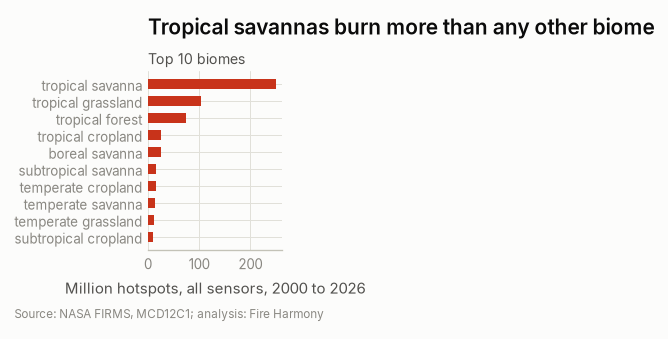

In [5]:
b = (s.groupby('biome').n_veg_all_time.sum() / 1e6).sort_values().tail(10)
print(f"tropical savanna share of all hotspots: {100 * s.loc[s.biome == 'tropical savanna', 'n_veg_all_time'].sum() / s.n_veg_all_time.sum():.0f}%")
fig, ax = plt.subplots(figsize=fh.SIZE['half'])
ax.barh(b.index, b.values, color=fh.EMBER[5], height=0.6)
fh.clean(ax, grid_axis='x'); ax.set_xlabel('Million hotspots, all sensors, 2000 to 2026')
fh.title(ax, 'Tropical savannas burn more than any other biome', 'Top 10 biomes')
fh.source(fig, 'Source: NASA FIRMS, MCD12C1; analysis: Fire Harmony')
fh.save(fig, FIG / 'fig06_fires_by_biome')
b.round(1)

## 5. Peat

Peat fires smoulder for weeks and cause most of the haze in South East Asia.

In [6]:
(s.groupby('country').peat_km2.sum() / 1e3).sort_values(ascending=False).head(10).round(1).rename('peat, thousand km2').to_frame()

,"peat, thousand km2"
country,
Russia,1083.4
Canada,876.3
Brazil,212.4
United States of America,157.5
Indonesia,139.3
Dem. Rep. Congo,90.8
China,86.9
Finland,51.7
Papua New Guinea,47.6


> **Key findings**
>
> - A level 5 hexagon covers about 253 km2. We use 413,699 of them, every place where a satellite ever saw a vegetation fire.
> - Our peat layer adds up to 4.23 million km2, the same as the published PEATMAP total. 3.26 million km2 of it lies in hexagons where a satellite saw a hotspot.
> - Our population layer gives 6.05 billion people in 2000 and 8.0 billion in 2020, close to the GPW totals.
> - Tropical savannas hold 42% of the world's hotspots, more than twice as many as the next biome (tropical grassland).